# Conejos Guardianes<br>

## 1. Instanciación del Entorno y Representación de Estados

La lógica de simulación dada por los archivos: `motor.py`, `algoritmos.py`, `memoria_ia.py`, `agente_ia.py` está desacoplada de la capa gráfica `interfaz.py`. Al crear una instancia de `Juego`, se configuran:
- `mapa_real`: matriz de `14x21` con valores `FUERA (0)`, `CAMINO (1)` y `META (2)`.
- `memoria`: mapa de conocimiento parcial definido principalmente por `DESCONOCIDO = -1` al iniciar y matriz de peligro normalizado por celda.
- `comandante`: agente estratégico basado en **utilidad esperada** y **Q-learning tabular**.
- `algoritmo_por_tipo`: mapeo táctico:`topo -> bfs_exploracion`, `mapache -> a_estrella`, `jabali/jefe -> dijkstra_pesimista`.

In [1]:
import os
import sys
from pathlib import Path

raices = [Path.cwd(), Path.cwd().parent, Path('/work')]
ruta_proyecto = None

for raiz in raices:
    if not raiz.exists():
        continue
    if (raiz / 'motor.py').exists():
        ruta_proyecto = raiz
        break
    encontrado = next(raiz.rglob('motor.py'), None)
    if encontrado is not None:
        ruta_proyecto = encontrado.parent
        break

if ruta_proyecto is None:
    raise FileNotFoundError(
        "No se encontró 'motor.py'"
    )

if str(ruta_proyecto) not in sys.path:
    sys.path.insert(0, str(ruta_proyecto))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import datos
import algoritmos
import laboratorio
from motor import Juego
juego = Juego(dificultad='normal')

print(f'Módulos cargados desde: {ruta_proyecto}')
print(f'Dimensiones del entorno: {juego.mapa_real.shape}')
print(f'Entrada: {datos.ENTRADA} | Meta : {datos.META_POS}')
print(f'Fase inicial: {juego.fase} | Ronda: {juego.ronda}')
print(f'Vida base: {juego.vida_base}/{juego.vida_maxima}')
print(f'Presupuesto Jugador: ${juego.presupuesto_jugador} | Presupuesto IA: ${juego.presupuesto_ia}')
print(f'Celdas conocidas por la IA al inicio: {juego.memoria.celdas_conocidas()} / {juego.mapa_real.size}')
print('\nAsignación de algoritmos por tropa:')
for tropa, alg in juego.algoritmo_por_tipo.items():
    print(f'  - {tropa:<8} -> {alg}')

Módulos cargados desde: /datasets/_deepnote_work
Dimensiones del entorno: (14, 21)
Entrada: (2, 19) | Meta : (13, 4)
Fase inicial: preparacion | Ronda: 1
Vida base: 7/7
Presupuesto Jugador: $100 | Presupuesto IA: $60
Celdas conocidas por la IA al inicio: 0 / 294

Asignación de algoritmos por tropa:
  - topo     -> bfs_exploracion
  - mapache  -> a_estrella
  - jabali   -> dijkstra_pesimista
  - jefe     -> dijkstra_pesimista


## 2. Métodos Principales del Entorno y Simulación *Headless*

Durante la fase `'preparacion'`, el jugador gestiona sus defensas mediante:
- `es_construible(fila, col)`: verifica si la celda es `FUERA` y no tiene torre.
- `colocar_torre(tipo, fila, col)`: construye una torre (`basica`, `reconocimiento`, `rapida`, `pesada`) si alcanza el presupuesto.
- `mejorar_torre(fila, col)` / `quitar_torre(fila, col)`: incrementa el nivel de daño (hasta nivel 3) o vende la torre.

Al ejecutar `iniciar_ronda()`, el comandante evalúa el riesgo, elige una mezcla de tropas y llena `cola_spawn`. Después, cada llamada a `juego.paso()` avanza **1 tick discreto** de simulación.

In [2]:
# Reiniciamos una partida limpia para que la celda sea reejecutable
juego = Juego(dificultad='normal')

defensas_iniciales = [
    ('reconocimiento', 3, 17),  # Detecta topos invisibles cerca de la entrada (2, 19)
    ('basica', 3, 18),          # Apoyo de daño temprano
    ('basica', 4, 15),          # Cobertura en el primer giro
    ('basica', 11, 3),          # Defensa final antes de la meta (13, 4)
]

for tipo, f, c in defensas_iniciales:
    ok = juego.colocar_torre(tipo, f, c)
    print(f'Colocar {tipo:<14} en ({f:2d}, {c:2d}) -> {"OK" if ok else "Falló"} (Saldo: ${juego.presupuesto_jugador})')

def simular_ronda(juego):
    """Ejecuta una ronda completa tick a tick sin abrir ventana gráfica."""
    if juego.fase == 'resumen':
        juego.siguiente_ronda()
    if not juego.iniciar_ronda():
        return
    while juego.fase == 'ronda':
        juego.paso()

for _ in range(6):
    if juego.fase in ('derrota', 'victoria'):
        break
    if juego.fase == 'resumen':
        juego.siguiente_ronda()
    if juego.ronda == 3 and juego.presupuesto_jugador >= 60:
        juego.colocar_torre('rapida', 11, 5)
    simular_ronda(juego)

df_rondas = pd.DataFrame([
    {
        'Ronda': h['ronda'],
        'Enviados': h['enviados'],
        'Llegaron': h['llegaron'],
        'Saciados': h['saciados'],
        'Composición': str(h['composicion']),
        'Celdas IA': h['celdas_conocidas'],
        'Caja IA ($)': h['presupuesto_ia'],
        'Vida Base': h['vida_base'],
    }
    for h in juego.historial_rondas
])
display(df_rondas)

Colocar reconocimiento en ( 3, 17) -> OK (Saldo: $70)
Colocar basica         en ( 3, 18) -> OK (Saldo: $60)
Colocar basica         en ( 4, 15) -> OK (Saldo: $50)
Colocar basica         en (11,  3) -> OK (Saldo: $40)


,Ronda,Enviados,Llegaron,Saciados,Composición,Celdas IA,Caja IA ($),Vida Base
0,1,4,2,2,"{'mapache': 2, 'topo': 2}",294,100,5
1,2,10,5,4,"{'mapache': 5, 'topo': 5}",294,80,0


## 3. Comparación Objetiva de los Algoritmos de Búsqueda (`laboratorio.py`)

El módulo `laboratorio` toma una fotografía exacta del entorno (`foto(juego, tipo, modo)`) y ejecuta los algoritmos sobre **la misma instancia** y con la misma función de costo $c(t, f, c) = 1 + 20 \cdot \text{riesgo}(t, f, c)$:
1. **BFS exploración**: búsqueda no informada (`deque`), ignora costos de peligro y camina solo por lo conocido hasta la frontera más cercana o la meta.
2. **Dijkstra pesimista**: búsqueda de costo uniforme (`heapq`), respeta los costos de peligro pero nunca pisa celdas `DESCONOCIDO`.
3. **A\* Manhattan**: búsqueda informada optimista con heurística admisible y consistente $h_M(n) = |\Delta f| + |\Delta c|$.
4. **A\* Euclidiana**: búsqueda informada optimista con heurística admisible menos informada $h_E(n) = \sqrt{\Delta f^2 + \Delta c^2}$.

In [3]:
for modo in ('conocido', 'completo'):
    snap = laboratorio.foto(juego, tipo='mapache', modo=modo)
    filas_activas = [f for f in snap['filas'] if f['nombre'] != 'BFS']
    df_lab = pd.DataFrame([
        {
            'Algoritmo': f['nombre'],
            'Estado': f['resultado'],
            'Pasos': f['largo'],
            'Costo Ruta': round(f['costo'], 2),
            'Óptima': f['optima'],
            'Generados': f['generados'],
            'Expandidos': f['expandidos'],
            'Frontera Máx': f['frontera_max'],
            'Tiempo (ms)': round(f['tiempo_ms'], 4),
        }
        for f in filas_activas
    ])
    print(f' Comparación en mapa {modo.upper()} (Ronda {snap["ronda"]}, celdas conocidas: {snap["conocidas"]}) ')
    display(df_lab)

 Comparación en mapa CONOCIDO (Ronda 2, celdas conocidas: 294) 


,Algoritmo,Estado,Pasos,Costo Ruta,Óptima,Generados,Expandidos,Frontera Máx,Tiempo (ms)
0,BFS exploracion,llega,30,48.96,True,126,124,7,0.4948
1,A* Manhattan,llega,30,48.96,True,72,64,8,0.2710
2,Dijkstra pesimista,llega,30,48.96,True,126,122,7,0.7040


 Comparación en mapa COMPLETO (Ronda 2, celdas conocidas: 294) 


,Algoritmo,Estado,Pasos,Costo Ruta,Óptima,Generados,Expandidos,Frontera Máx,Tiempo (ms)
0,BFS exploracion,llega,30,48.96,True,126,124,7,0.5718
1,A* Manhattan,llega,30,48.96,True,72,64,8,0.3170
2,Dijkstra pesimista,llega,30,48.96,True,126,122,7,0.6722


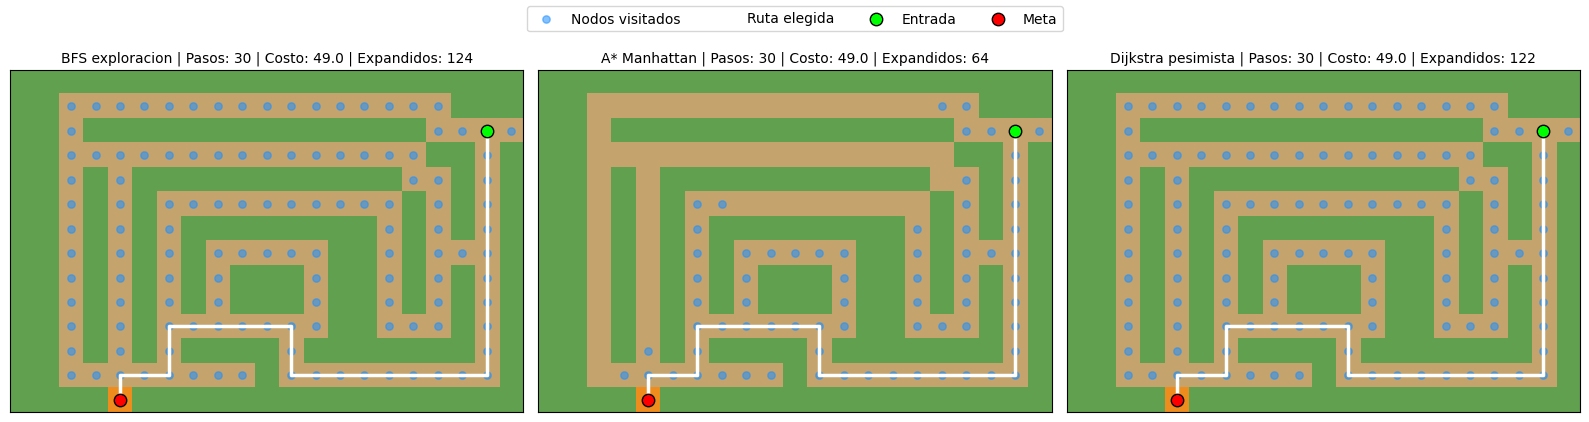

In [4]:
snap_completo = laboratorio.foto(juego, tipo='mapache', modo='completo')
filas_vis = [f for f in snap_completo['filas'] if f['nombre'] != 'BFS']

fig, axes = plt.subplots(1, max(1, len(filas_vis)), figsize=(16, 4.5))
axes = np.atleast_1d(axes).ravel()

colores_terreno = {
    datos.FUERA: [0.38, 0.63, 0.31],
    datos.CAMINO: [0.77, 0.64, 0.43],
    datos.META: [0.94, 0.55, 0.12],
}

img_mapa = np.zeros((*juego.mapa_real.shape, 3))
for val, rgb in colores_terreno.items():
    img_mapa[juego.mapa_real == val] = rgb

for ax, f in zip(axes, filas_vis):
    ax.imshow(img_mapa)
    if f['visitados']:
        vf, vc = zip(*f['visitados'])
        ax.scatter(vc, vf, c='dodgerblue', s=28, alpha=0.55, label='Nodos visitados')

    ruta = [datos.ENTRADA] + f['camino']
    if ruta:
        rf, rc = zip(*ruta)
        ax.plot(rc, rf, color='white', linewidth=2.5, label='Ruta elegida')

    ax.scatter([datos.ENTRADA[1]], [datos.ENTRADA[0]], c='lime', edgecolors='black', s=80, zorder=5, label='Entrada')
    ax.scatter([datos.META_POS[1]], [datos.META_POS[0]], c='red', edgecolors='black', s=80, zorder=5, label='Meta')
    ax.set_title(
        f"{f['nombre']} | Pasos: {f['largo']} | Costo: {f['costo']:.1f} | Expandidos: {f['expandidos']}",
        fontsize=10,
    )
    ax.set_xticks([])
    ax.set_yticks([])


handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, frameon=True)
plt.tight_layout(rect=[0, 0, 1, 0.94])


plt.show()

## 4. Funcionamiento Interno de la IA Estratégica (`MemoriaIA` y `Comandante`)

Además del pathfinding táctico, la IA aprende qué celdas son peligrosas y qué composición de oleada rinde mejor:
1. **Mapa de Riesgo (`MemoriaIA`)**: normaliza el daño recibido por celda entre las visitas (`peligro / pasadas`) con ventana deslizante de 7 rondas.
2. **Agente Basado en Utilidad (`Comandante.evaluar`)**: calcula $P(\text{llegar}) = \max(0.05, 1 - \text{riesgo})$ y compra cada tropa solo si $P(\text{llegar}) \times \text{VALOR\_LLEGADA} \ge \text{costo}$.
3. **Aprendizaje por Refuerzo (`Q-Learning`)**: actualiza la matriz $Q(s, a)$ entre rondas donde $s$ es la mezcla previa (`enjambre`, `tanque`, `mixta`) y $a$ la mezcla elegida.

Evaluación de Utilidad Esperada para la próxima ronda


,largo,eta,riesgo,prob,compra,explorando
Tropa,,,,,,
topo,30,60,0.257143,0.742857,True,False
mapache,30,30,0.947751,0.052249,False,False
jabali,30,90,0.000000,1.000000,True,False
jefe,30,90,0.000000,1.000000,False,False



 Tabla Q del Comandante (Valores Q(s, a)) 


,enjambre,tanque,mixta
Estado (Mezcla anterior),,,
enjambre,1.000,1.0,1.0
tanque,1.000,1.0,1.0
mixta,0.958,1.0,1.0


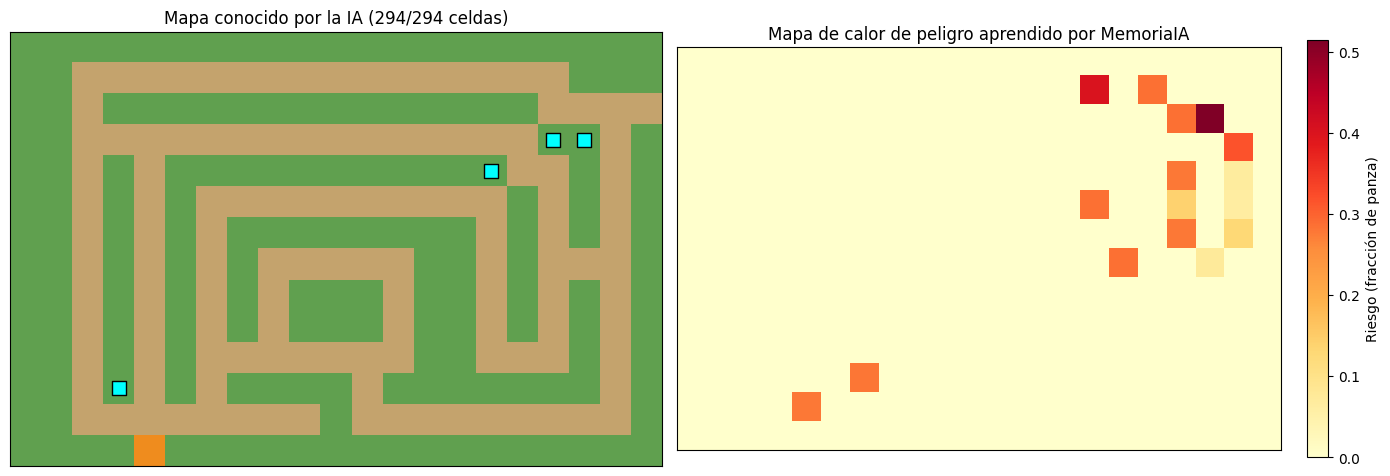

In [5]:
# 1. Evaluación previa del Agente de Utilidad
ev_actual = juego.comandante.evaluar(juego.memoria, juego.algoritmo_por_tipo)
df_utilidad = pd.DataFrame.from_dict(ev_actual, orient='index')
df_utilidad.index.name = 'Tropa'
print('Evaluación de Utilidad Esperada para la próxima ronda')
display(df_utilidad)

# 2. Tabla Q aprendida por el Comandante
df_q = pd.DataFrame(juego.comandante.q).T
df_q.index.name = 'Estado (Mezcla anterior)'
print('\n Tabla Q del Comandante (Valores Q(s, a)) ')
display(df_q.round(3))

# 3. Visualización del Mapa Conocido y del Mapa de Calor de Riesgo
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

img_conocido = np.zeros((*juego.mapa_real.shape, 3))
colores_con = {**colores_terreno, datos.DESCONOCIDO: [0.08, 0.08, 0.11]}
for val, rgb in colores_con.items():
    img_conocido[juego.memoria.mapa_conocido == val] = rgb
ax1.imshow(img_conocido)
for idx, t in enumerate(juego.torres):
    ax1.scatter([t.col], [t.fila], marker='s', s=90, c='cyan', edgecolors='black', label='Torre' if idx == 0 else '')
ax1.set_title(f'Mapa conocido por la IA ({juego.memoria.celdas_conocidas()}/{juego.mapa_real.size} celdas)')
ax1.set_xticks([]); ax1.set_yticks([])

mapa_riesgo = np.zeros(juego.mapa_real.shape, dtype=float)
for f in range(mapa_riesgo.shape[0]):
    for c in range(mapa_riesgo.shape[1]):
        mapa_riesgo[f, c] = max(juego.memoria.riesgo(t, (f, c)) for t in ('topo', 'mapache', 'jabali'))

im = ax2.imshow(mapa_riesgo, cmap='YlOrRd', vmin=0, vmax=max(0.5, mapa_riesgo.max()))
plt.colorbar(im, ax=ax2, fraction=0.032, pad=0.04, label='Riesgo (fracción de panza)')
ax2.set_title('Mapa de calor de peligro aprendido por MemoriaIA')
ax2.set_xticks([]); ax2.set_yticks([])

plt.tight_layout()
plt.show()

## 5. Ejecución (`main.py`)


In [6]:
!pip install pygame
!python main.py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.0/14.0 MB 81.9 MB/s  0:00:00

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
/root/venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
pygame 2.6.1 (SDL 2.28.4, Python 3.13.18)
Hello from the pygame community. https://www.pygame.org/contribute.html
^C


KeyboardInterrupt: 

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=fc60015e-fa72-429d-a1bc-9b37f32f17b2' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>